# Cerro Alegre — SAM 3

## 1. Instalación y entorno

In [4]:
import sys
import subprocess
from pathlib import Path

repo = Path("/content/sam3")

# Clonar SAM 3 si todavía no está descargado.
if not (repo / "sam3" / "model_builder.py").is_file():
    print("Descargando SAM 3...", flush=True)
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/facebookresearch/sam3.git",
        str(repo)
    ], check=True)

# Instalar SAM 3 y sus dependencias.
print("Instalando SAM 3...", flush=True)
subprocess.run([
    sys.executable, "-m", "pip", "install", "-e", str(repo)
], check=True)

# Instalar utilidades geoespaciales.
print("Instalando librerías geoespaciales...", flush=True)
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "rasterio", "geopandas", "shapely",
    "scipy", "matplotlib", "pyogrio", "huggingface_hub"
], check=True)

print("Instalación finalizada.")

Instalando SAM 3...
Instalando librerías geoespaciales...
Instalación finalizada.


In [1]:
import sys
from pathlib import Path
repo=Path('/content/sam3')
if str(repo) not in sys.path: sys.path.insert(0,str(repo))
import numpy as np
import pandas as pd
import torch
import rasterio
import geopandas as gpd
import shapely, scipy
print('Python:',sys.version.split()[0],'NumPy:',np.__version__,'pandas:',pd.__version__,'Torch:',torch.__version__)
print('CUDA:',torch.cuda.is_available())
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor
print('Importaciones correctas, repositorio:',repo)


Python: 3.13.16 NumPy: 2.5.5 pandas: 2.2.3 Torch: 2.14.1+cu130
CUDA: True


/content/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/content/sam3/sam3/model/model_misc.py:71: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()


Importaciones correctas, repositorio: /content/sam3


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## 2. Configuración y preparación compartida

In [3]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
DATOS = Path('/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos')
RASTER = DATOS/'Cerro_Alegre_Censo_Clip_uint8_global.tif'
CENSO_SHP = DATOS/'Censo_CerroAlegre_parcelas_12-15-16.shp'
SALIDA = DATOS.parent/'SAM3_CerroAlegre_Resultados'
assert DATOS.is_dir(),f'Falta carpeta: {DATOS}'
for p in (RASTER,CENSO_SHP,*[CENSO_SHP.with_suffix(e) for e in ('.shx','.dbf','.prj')]):
    if not p.is_file():raise FileNotFoundError(str(p))
SALIDA.mkdir(parents=True,exist_ok=True)
TILE=768
MARGIN=96
MAX_TILES=4
PROMPTS=['tree crown','individual tree canopy']
SCORE_MIN=0.35
MIN_PIXELS=18
DIST_MATCH_M=2.5
MIN_VALID_FRAC=0.30
print('Datos:',DATOS,'\nOrtofoto:',RASTER.name,'\nSHP:',CENSO_SHP.name,'\nSalidas:',SALIDA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Datos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos 
Ortofoto: Cerro_Alegre_Censo_Clip_uint8_global.tif 
SHP: Censo_CerroAlegre_parcelas_12-15-16.shp 
Salidas: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_Resultados


In [4]:
from google.colab import userdata
from huggingface_hub import login, hf_hub_download
from huggingface_hub.errors import GatedRepoError
TOKEN=userdata.get('HF_TOKEN')
if not TOKEN:raise RuntimeError('Guardá HF_TOKEN en los Secretos de Colab y habilitá su acceso al notebook.')
login(token=TOKEN,add_to_git_credential=False)
# Comprobar acceso al checkpoint real, no a config.json que puede no existir.
try:
    from huggingface_hub import list_repo_files
    files=list_repo_files('facebook/sam3',token=TOKEN)
    print('Acceso al repositorio SAM 3:',len(files),'archivos listados')
except Exception as e:
    raise RuntimeError('No hay acceso autorizado a facebook/sam3. Revisar https://huggingface.co/facebook/sam3 y esperar la aprobación.') from e


Acceso al repositorio SAM 3: 12 archivos listados


In [5]:
import os, math, gc, json
import numpy as np, pandas as pd, rasterio, geopandas as gpd, torch
import matplotlib.pyplot as plt
from rasterio.windows import Window, transform as window_transform
from PIL import Image
from shapely.geometry import box
from shapely.ops import unary_union
from scipy.optimize import linear_sum_assignment
src=rasterio.open(RASTER)
print('TIFF:',src.width,src.height,'CRS:',src.crs,'bandas:',src.count,'NoData:',src.nodata,'dtype:',src.dtypes)
assert src.count>=3 and src.crs and all(dt=='uint8' for dt in src.dtypes[:3]),'Esperado RGB uint8 georreferenciado'
assert src.crs.is_projected and src.crs.linear_units.lower() in ('metre','meter','metres','meters'),'La distancia requiere CRS en metros.'
truth=gpd.read_file(CENSO_SHP)
assert truth.crs,'Falta CRS del SHP (.prj)'
truth=truth.to_crs(src.crs)
truth=truth[truth.geometry.notna() & (~truth.geometry.is_empty)].copy()
truth=truth.explode(index_parts=False,ignore_index=True).reset_index(drop=True)
assert truth.geom_type.eq('Point').all(),'Se esperaban puntos individuales en el censo'
print('Árboles censados:',len(truth))
# Inspección explícita del NoData sin rellenar uint8 con NaN
with rasterio.open(RASTER) as test:
    sm=test.read([1,2,3],out_shape=(3,256,256),masked=True)
    fv=sm.astype('float32').filled(np.nan)
    print('Muestra: % NoData',round(100*np.ma.getmaskarray(sm).any(axis=0).mean(),1),'rango válido:',(float(np.nanmin(fv)),float(np.nanmax(fv))) if np.isfinite(fv).any() else 'sin datos')


TIFF: 2098 6373 CRS: EPSG:32721 bandas: 3 NoData: 0.0 dtype: ('uint8', 'uint8', 'uint8')
Árboles censados: 2917
Muestra: % NoData 65.2 rango válido: (1.0, 255.0)


In [6]:
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor
model=build_sam3_image_model()
model.eval()
processor=Sam3Processor(model)
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('SAM 3 cargado | GPU:',torch.cuda.get_device_name(0),'| autocast:',DTYPE)


config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.pt: reconstructing file:   0%|          |  0.00B / 3.45GB            

sam3.pt: downloading bytes:           |  0.00B            

SAM 3 cargado | GPU: Tesla T4 | autocast: torch.bfloat16


## 3. Experimento con indicaciones textuales

In [7]:
# Desactivar temporalmente el filtro interno de SAM 3
processor.set_confidence_threshold(0.0)

print("Umbral interno de SAM 3:",
      processor.confidence_threshold)

Umbral interno de SAM 3: 0.0


In [8]:
SCORE_MIN = 0.20
MAX_TILES = 1

Teselas con árboles: 13 | Seleccionadas: 1


/tmp/ipykernel_6705/252659589.py:39: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pil=Image.fromarray(rgb,mode='RGB')


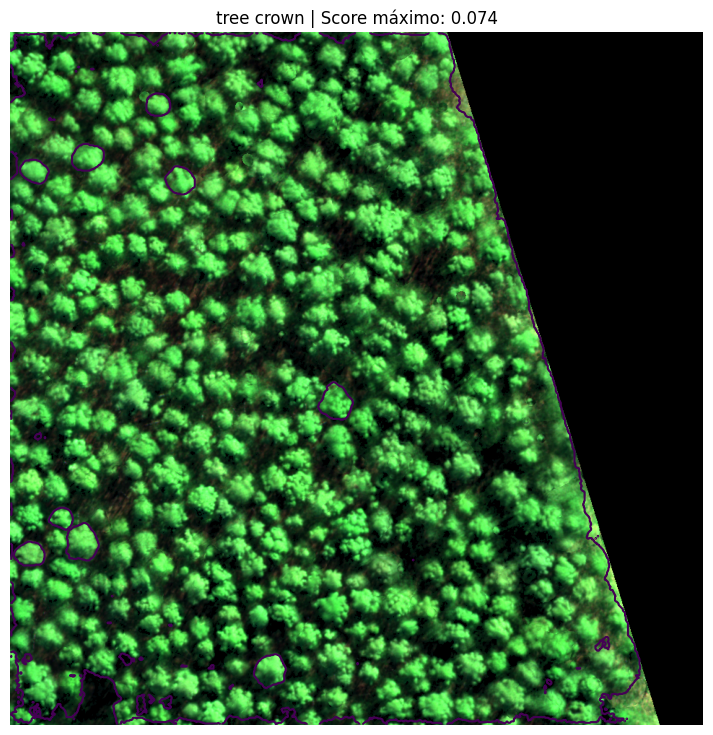

Tesela 1, prompt=tree crown: máscaras SIN filtrar=200, máximo score=0.07421875


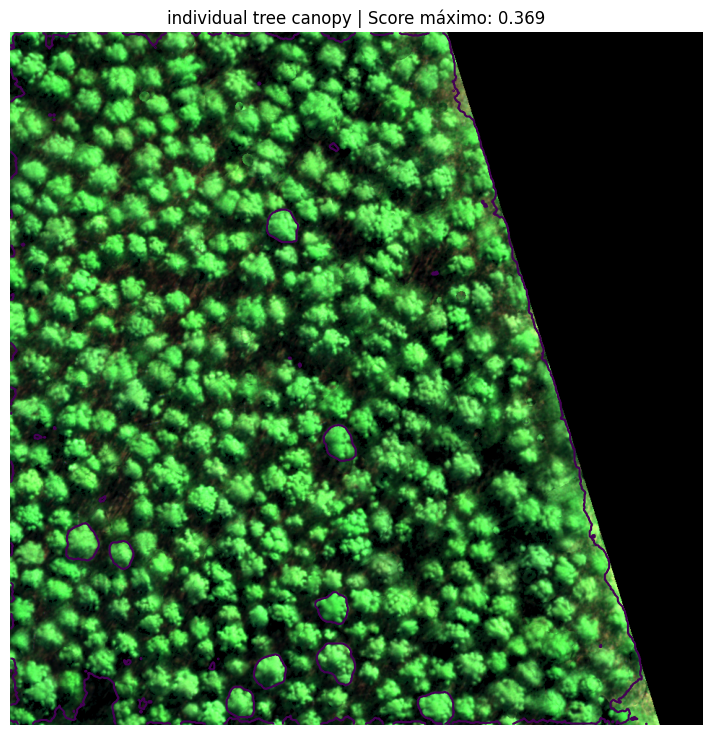

Tesela 1, prompt=individual tree canopy: máscaras SIN filtrar=200, máximo score=0.369140625
Tesela 1/1: GT=302, propuestas filtradas=7
TOTAL propuestas: 7


In [9]:
from rasterio.features import shapes
from shapely.geometry import shape

def rgb_tile(win):
    a=src.read([1,2,3],window=win,masked=True)
    invalid=np.ma.getmaskarray(a).any(axis=0)
    rgb=np.moveaxis(a.filled(0).astype(np.uint8),0,-1)
    invalid |= ~np.all(np.isfinite(rgb),axis=2)
    rgb[invalid]=0
    return rgb,invalid

def mask_polygon(mask,transform):
    ps=[shape(geom) for geom,val in shapes(mask.astype('uint8'),mask=mask,transform=transform) if val==1]
    ps=[p for p in ps if not p.is_empty and p.area>0]
    return max(ps,key=lambda p:p.area) if ps else None

# Selección de teselas representativas con más puntos censados
tile_candidates=[]
for y in range(0,src.height,TILE):
    for x in range(0,src.width,TILE):
        w=min(TILE,src.width-x);h=min(TILE,src.height-y)
        region=box(*rasterio.windows.bounds(Window(x,y,w,h),src.transform))
        gt_count=int(truth.geometry.apply(region.covers).sum())
        if gt_count==0:continue
        sample=src.read(1,window=Window(x,y,w,h),out_shape=(min(128,h),min(128,w)),masked=True)
        valid_frac=float((~np.ma.getmaskarray(sample)).mean())
        if valid_frac>=MIN_VALID_FRAC:tile_candidates.append((gt_count,valid_frac,x,y,w,h))
tile_candidates.sort(key=lambda z:(z[0],z[1]),reverse=True)
if not tile_candidates:raise RuntimeError('No hay teselas con puntos censados y suficiente imagen válida: comprobar alineación CRS y NoData.')
selected=tile_candidates if MAX_TILES is None else tile_candidates[:MAX_TILES]
print('Teselas con árboles:',len(tile_candidates),'| Seleccionadas:',len(selected))

rows=[];tile_records=[];diagnostics=[]
for k,(gt_count,vfrac,x,y,w,h) in enumerate(selected,1):
    x0=max(0,x-MARGIN);y0=max(0,y-MARGIN)
    x1=min(src.width,x+w+MARGIN);y1=min(src.height,y+h+MARGIN)
    win=Window(x0,y0,x1-x0,y1-y0)
    rgb,invalid=rgb_tile(win)
    pil=Image.fromarray(rgb,mode='RGB')
    wt=window_transform(win,src.transform)
    core=box(*rasterio.windows.bounds(Window(x,y,w,h),src.transform))
    before=len(rows)
    with torch.inference_mode(),torch.autocast(device_type='cuda',dtype=DTYPE):
        state=processor.set_image(pil)
        for phrase in PROMPTS:
            result=processor.set_text_prompt(state=state,prompt=phrase)
            masks=result['masks'].detach().float().cpu().numpy()
            scores=result['scores'].detach().float().cpu().numpy().reshape(-1)
            import matplotlib.pyplot as plt

            # Visualizar las 10 mejores máscaras de cada prompt
            if len(scores) > 0:
                top_idx = np.argsort(scores)[::-1][:10]

                fig, ax = plt.subplots(figsize=(9, 9))
                ax.imshow(pil)

                for idx in top_idx:
                    mascara = np.squeeze(masks[idx]) > 0.5

                    if mascara.shape != (pil.height, pil.width):
                        continue

                    ax.contour(
                        mascara.astype(float),
                        levels=[0.5],
                        linewidths=1.5
                    )

                ax.set_title(
                    f"{phrase} | Score máximo: {scores.max():.3f}"
                )
                ax.axis("off")
                plt.show()
            diagnostics.append({'tile':k,'prompt':phrase,'raw_masks':len(scores),'max_score':float(scores.max()) if len(scores) else None,'above_threshold':int((scores>=SCORE_MIN).sum())})
            print(f'Tesela {k}, prompt={phrase}: máscaras SIN filtrar={len(scores)}, máximo score={scores.max() if len(scores) else "ninguno"}')
            for m,s in zip(masks,scores):
                s=float(s)
                if s<SCORE_MIN:continue
                m=np.squeeze(m)>0.5
                if m.shape!=invalid.shape:raise RuntimeError(f'Tamaño máscara {m.shape} versus RGB {invalid.shape}')
                m[invalid]=False
                if m.sum()<MIN_PIXELS:continue
                geom=mask_polygon(m,wt)
                if geom is None or not core.covers(geom.centroid):continue
                rows.append({'tile_id':k,'prompt':phrase,'score':s,'geometry':geom})
    tile_records.append({'tile_id':k,'x':x,'y':y,'w':w,'h':h,'gt_count':gt_count,'valid_frac':vfrac,'n_predictions':len(rows)-before})
    print(f'Tesela {k}/{len(selected)}: GT={gt_count}, propuestas filtradas={len(rows)-before}')
    del pil,rgb,state,result,masks,scores
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
print('TOTAL propuestas:',len(rows))
pd.DataFrame(diagnostics).to_csv(SALIDA/'diagnostico_prompts.csv',index=False)
if not rows:print('CERO PROPUESTAS. Revisar diagnostico_prompts.csv y la visualización antes de informar métricas.')


### 3.1 Eliminar duplicados y evaluar el censo

In [10]:
pred0=gpd.GeoDataFrame(rows,geometry='geometry',crs=src.crs)
def dedup(gdf,threshold=0.50):
    if gdf.empty:return gdf.copy()
    ordered=gdf.sort_values('score',ascending=False).reset_index(drop=True)
    keep=[]
    for idx,row in ordered.iterrows():
        g=row.geometry
        duplicated=False
        for j in keep:
            h=ordered.loc[j,'geometry']
            if g.intersects(h) and g.intersection(h).area/max(g.union(h).area,1e-12)>=threshold:
                duplicated=True;break
        if not duplicated:keep.append(idx)
    return ordered.iloc[keep].reset_index(drop=True)
pred=dedup(pred0)
pred['tree_id']=np.arange(1,len(pred)+1)
print('Predicciones después de eliminar duplicados:',len(pred))


Predicciones después de eliminar duplicados: 7


In [11]:
# Comparación solo en núcleos de teselas PROCESADAS, sin doble contabilizar árbol.
cores=[box(*rasterio.windows.bounds(Window(t['x'],t['y'],t['w'],t['h']),src.transform)) for t in tile_records]
if not cores:raise RuntimeError('Sin teselas procesadas')
coverage=unary_union(cores)
truth_eval=truth[truth.geometry.apply(coverage.covers)].copy().reset_index(drop=True)
pred_eval=pred[pred.geometry.centroid.apply(coverage.covers)].copy().reset_index(drop=True) if len(pred) else pred.copy()
A=len(truth_eval);B=len(pred_eval)
valid=np.zeros((A,B),dtype=bool)
cost=np.full((A,B),1e9,dtype=float)
for i,pt in enumerate(truth_eval.geometry):
    for j,poly in enumerate(pred_eval.geometry):
        dist=pt.distance(poly.centroid)
        if poly.covers(pt) or dist<=DIST_MATCH_M:
            valid[i,j]=True
            cost[i,j]=dist+(0 if poly.covers(pt) else DIST_MATCH_M)
if A and B:
    # Matriz de asignación con coste prohibitivo para pares inválidos;
    # las filas/columnas ficticias permiten maximizar coincidencias válidas.
    N=A+B; C=np.zeros((N,N));C[:A,:B]=np.where(valid,cost,1e8)
    C[:A,B:]=1e5;C[A:,:B]=1e5
    rr,cc=linear_sum_assignment(C)
    matches=[(int(i),int(j),float(truth_eval.geometry.iloc[i].distance(pred_eval.geometry.iloc[j].centroid))) for i,j in zip(rr,cc) if i<A and j<B and valid[i,j]]
else:matches=[]
TP=len(matches);FP=B-TP;FN=A-TP
precision=TP/(TP+FP) if TP+FP else 0.0
recall=TP/(TP+FN) if TP+FN else 0.0
f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
metrics=dict(n_gt=A,n_pred=B,TP=TP,FP=FP,FN=FN,precision=precision,recall=recall,F1=f1,
             error_conteo=B-A,error_conteo_abs=abs(B-A),error_conteo_pct=100*abs(B-A)/A if A else None,
             score_min=SCORE_MIN,dist_match_m=DIST_MATCH_M,tile=TILE,n_tiles=len(cores),prompts='; '.join(PROMPTS))
print(pd.Series(metrics).to_string())


n_gt                                               302
n_pred                                               7
TP                                                   7
FP                                                   0
FN                                                 295
precision                                          1.0
recall                                        0.023179
F1                                            0.045307
error_conteo                                      -295
error_conteo_abs                                   295
error_conteo_pct                             97.682119
score_min                                          0.2
dist_match_m                                       2.5
tile                                               768
n_tiles                                              1
prompts             tree crown; individual tree canopy


In [12]:
metricas_textuales = metrics.copy()
print('Métricas textuales registradas para la comparación final.')

Métricas textuales registradas para la comparación final.


### 3.2 Exportación y visualización del experimento textual

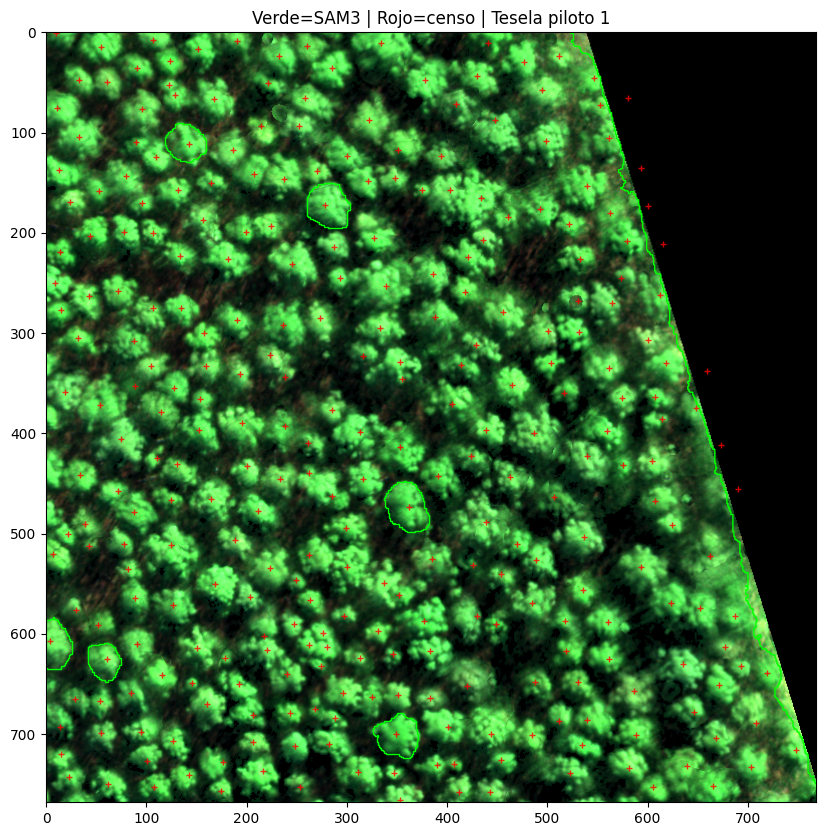

Resultados guardados: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_Resultados


In [13]:
from matplotlib.patches import Polygon as PatchPolygon
from rasterio.transform import rowcol
out=Path(SALIDA)
if len(pred):
    pred.to_file(out/'sam3_copas_pred.gpkg',driver='GPKG')
    ptspred=pred.copy();ptspred.geometry=ptspred.geometry.centroid
    ptspred.to_file(out/'sam3_centros_pred.gpkg',driver='GPKG')
if len(truth_eval):truth_eval.to_file(out/'sam3_censo_piloto.gpkg',driver='GPKG')
pd.DataFrame(tile_records).to_csv(out/'teselas.csv',index=False)
pd.DataFrame(matches,columns=['idx_gt','idx_pred','distancia_m']).to_csv(out/'matches.csv',index=False)
pd.DataFrame([metrics]).to_csv(out/'metricas_sam3.csv',index=False)
with open(out/'config_metricas.json','w') as f:json.dump(metrics,f,indent=2)
# Vista RGB y polígonos predichos + puntos del censo, SIEMPRE (incluso cero predicciones)
first=tile_records[0]; x=first['x'];y=first['y'];w=first['w'];h=first['h']
win=Window(x,y,w,h); rgb,_=rgb_tile(win)
fig,ax=plt.subplots(figsize=(10,10));ax.imshow(rgb)
for _,r in pred.iterrows():
    if r.tile_id!=first['tile_id']:continue
    xy=[(rowcol(src.transform,gx,gy)[1]-x,rowcol(src.transform,gx,gy)[0]-y) for gx,gy in r.geometry.exterior.coords]
    ax.add_patch(PatchPolygon(xy,fill=False,edgecolor='lime',linewidth=1))
for geom in truth_eval.geometry:
    rr,cc=rowcol(src.transform,geom.x,geom.y)
    if 0<=cc-x<w and 0<=rr-y<h:ax.plot(cc-x,rr-y,'r+',markersize=5,alpha=.8)
ax.set(xlim=(0,w),ylim=(h,0),title='Verde=SAM3 | Rojo=censo | Tesela piloto 1')
plt.savefig(out/'preview_primera_tesela.png',dpi=170,bbox_inches='tight');plt.show()
print('Resultados guardados:',out)


## 4. Experimento con una copa como indicación visual

### 4.1 Configuración específica de los ejemplos visuales

In [14]:
COPAS_GPKG = DATOS/'copas_totales_corregidas_cerro_alegre.gpkg'
CAPA_COPAS = None
SALIDA = DATOS.parent/'SAM3_CerroAlegre_VisualPrompt_Copas_Resultados'
assert DATOS.is_dir(),f'Falta carpeta: {DATOS}'
for p in (RASTER,CENSO_SHP,COPAS_GPKG,*[CENSO_SHP.with_suffix(e) for e in ('.shx','.dbf','.prj')]):
    if not p.is_file():raise FileNotFoundError(str(p))
SALIDA.mkdir(parents=True,exist_ok=True)
TILE=512
MARGIN=96
MAX_TILES=2
BOX_PADDING=1.08   # expandir 8% caja derivada del polígono
SCORE_MIN=0.15
MIN_PIXELS=18
DIST_MATCH_M=2.5
MIN_VALID_FRAC=0.30  # evitar teselas dominadas por NoData
print('Datos:',DATOS,'\nOrtofoto:',RASTER.name,'\nSHP:',CENSO_SHP.name,'\nSalidas:',SALIDA)


Datos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos 
Ortofoto: Cerro_Alegre_Censo_Clip_uint8_global.tif 
SHP: Censo_CerroAlegre_parcelas_12-15-16.shp 
Salidas: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados


### 4.2 Lectura y validación de las copas delineadas

In [15]:
# Copas manualmente delineadas
import pyogrio
capas=pyogrio.list_layers(str(COPAS_GPKG))[:, 0].tolist()
print('Capas del GPKG:',capas)
if CAPA_COPAS is None and len(capas)!=1:
    raise ValueError('El GPKG tiene varias capas: definí CAPA_COPAS con la capa de copas.')
copas=gpd.read_file(COPAS_GPKG,layer=CAPA_COPAS or capas[0], engine="pyogrio")
if copas.crs is None:raise ValueError('El archivo de copas no tiene CRS definido')
copas=copas.to_crs(src.crs)
copas=copas[copas.geometry.notna() & (~copas.geometry.is_empty)].copy()
copas=copas.explode(index_parts=False,ignore_index=True)
# Geometrías inválidas no se corrigen silenciosamente; advertir
if not copas.is_valid.all():
    raise ValueError(f'Hay {(~copas.is_valid).sum()} copas inválidas: corregilas antes de probar')
copas=copas[copas.geom_type.isin(['Polygon','MultiPolygon'])].reset_index(drop=True)
if not len(copas):raise ValueError('No hay polígonos de copa en el GPKG')
print('Copas manuales:',len(copas))


Capas del GPKG: ['capas_totales_corregidas']
Copas manuales: 999


### 4.3 Selección de copas y teselas para la prueba visual

Teselas elegibles: 23
Teselas piloto: 2


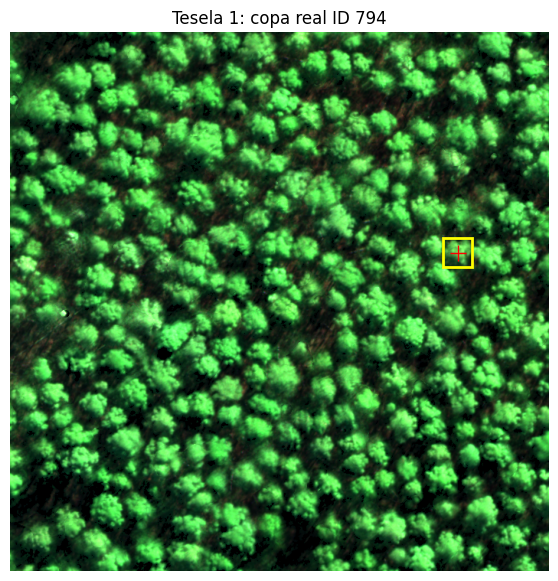

Tesela 2: sin ejemplos válidos
Ejemplos visuales preparados: 1


In [16]:
from rasterio.features import shapes
from rasterio.transform import rowcol
from shapely.geometry import shape
from matplotlib.patches import Rectangle

def rgb_tile(win):
    a = src.read([1, 2, 3], window=win, masked=True)
    invalid = np.ma.getmaskarray(a).any(axis=0)
    rgb = np.moveaxis(a.filled(0).astype(np.uint8), 0, -1)
    rgb[invalid] = 0
    return rgb, invalid

def mask_polygon(mask, transform):
    polys = [
        shape(g)
        for g, val in shapes(
            mask.astype("uint8"),
            mask=mask,
            transform=transform
        )
        if val == 1
    ]
    polys = [p for p in polys if not p.is_empty and p.area > 0]
    return max(polys, key=lambda p: p.area) if polys else None

# Seleccionar teselas con árboles censados
tile_candidates = []

for y in range(0, src.height, TILE):
    for x in range(0, src.width, TILE):
        w = min(TILE, src.width - x)
        h = min(TILE, src.height - y)

        core = box(*rasterio.windows.bounds(
            Window(x, y, w, h), src.transform
        ))

        gt_count = int(truth.geometry.apply(core.covers).sum())
        if gt_count < 2:
            continue

        sample = src.read(
            1,
            window=Window(x, y, w, h),
            out_shape=(min(128, h), min(128, w)),
            masked=True
        )

        valid_frac = float(
            (~np.ma.getmaskarray(sample)).mean()
        )

        if valid_frac >= MIN_VALID_FRAC:
            tile_candidates.append(
                (gt_count, valid_frac, x, y, w, h)
            )

tile_candidates.sort(
    key=lambda z: (z[0], z[1]), reverse=True
)

selected = (
    tile_candidates if MAX_TILES is None
    else tile_candidates[:MAX_TILES]
)

print("Teselas elegibles:", len(tile_candidates))
print("Teselas piloto:", len(selected))

# Construir cajas desde las copas dibujadas
examples = []

for k, (gt_count, vfrac, x, y, w, h) in enumerate(selected, 1):

    x0, y0 = max(0, x-MARGIN), max(0, y-MARGIN)
    x1 = min(src.width, x+w+MARGIN)
    y1 = min(src.height, y+h+MARGIN)

    win = Window(x0, y0, x1-x0, y1-y0)
    rgb, invalid = rgb_tile(win)
    H, W = rgb.shape[:2]

    core = box(*rasterio.windows.bounds(
        Window(x, y, w, h), src.transform
    ))

    candidatos = copas[
        copas.geometry.apply(core.covers)
    ]

    elegibles = []

    for crown_idx, poligono in candidatos.geometry.items():

        if poligono.is_empty or poligono.area <= 0:
            continue

        # Bounding box real del polígono
        minx, miny, maxx, maxy = poligono.bounds

        r0, c0 = rowcol(src.transform, minx, maxy)
        r1, c1 = rowcol(src.transform, maxx, miny)

        cx = (c0 + c1) / 2
        cy = (r0 + r1) / 2

        padding = globals().get("BOX_PADDING", 1.0)
        bw = max(1, abs(c1-c0)) * padding
        bh = max(1, abs(r1-r0)) * padding

        left, right = cx-bw/2, cx+bw/2
        top, bottom = cy-bh/2, cy+bh/2

        if not (
            x+2 <= left < right <= x+w-2
            and y+2 <= top < bottom <= y+h-2
        ):
            continue

        lx0 = int(np.floor(left-x0))
        lx1 = int(np.ceil(right-x0))
        ly0 = int(np.floor(top-y0))
        ly1 = int(np.ceil(bottom-y0))

        if lx0 < 0 or ly0 < 0 or lx1 > W or ly1 > H:
            continue

        if invalid[ly0:ly1, lx0:lx1].any():
            continue

        # Verificar correspondencia con un árbol censado
        ids = truth.index[
            truth.geometry.apply(poligono.covers)
        ].tolist()

        if len(ids) != 1:
            continue

        pc, pr = cx-x0, cy-y0

        norm_box = [
            float(pc/W),
            float(pr/H),
            float(bw/W),
            float(bh/H)
        ]

        elegibles.append((
            crown_idx, poligono, ids,
            pc, pr, bw, bh, norm_box
        ))

    if not elegibles:
        print(f"Tesela {k}: sin ejemplos válidos")
        continue

    crown_idx, poligono, ids, pc, pr, bw, bh, norm_box = (
        elegibles[len(elegibles)//2]
    )

    examples.append(dict(
        tile_id=k,
        gt_count=gt_count,
        valid_frac=vfrac,
        x=x, y=y, w=w, h=h,
        win=win,
        example_index=int(crown_idx),
        example_polygon=poligono,
        excluded_truth_ids=[int(i) for i in ids],
        example_col=pc,
        example_row=pr,
        box_norm=norm_box
    ))

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(rgb)

    ax.add_patch(Rectangle(
        (pc-bw/2, pr-bh/2),
        bw, bh,
        fill=False,
        edgecolor="yellow",
        linewidth=2
    ))

    ax.plot(pc, pr, "r+", markersize=12)
    ax.set_title(f"Tesela {k}: copa real ID {crown_idx}")
    ax.axis("off")
    plt.show()

assert examples, "No se encontraron copas válidas"

print("Ejemplos visuales preparados:", len(examples))

### 4.4 Inferencia mediante caja positiva

Tesela 1: 200 candidatas | score máximo: 0.9375


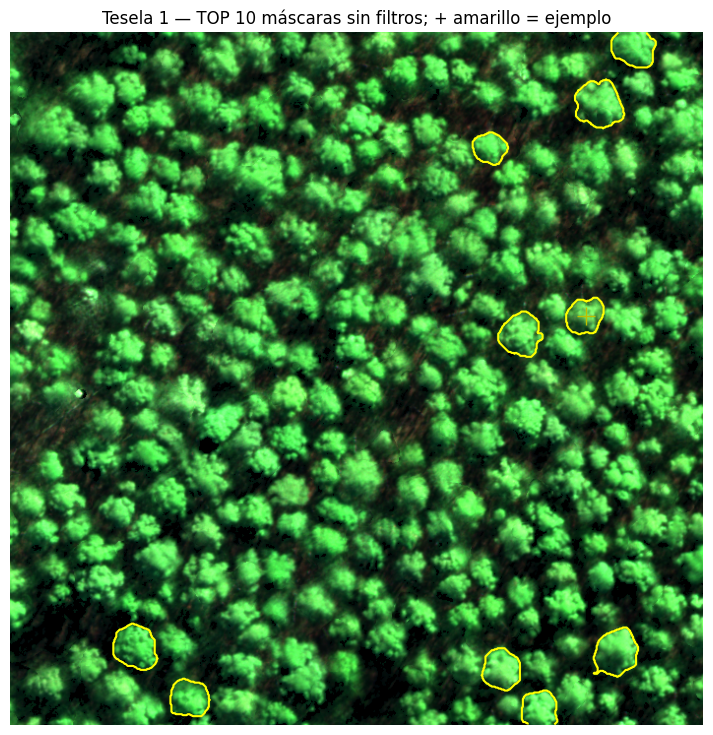

Propuestas retenidas (sin copa de ejemplo): 101
TOTAL propuestas: 101


In [17]:
from rasterio.windows import transform as window_transform
rows=[];tile_records=[];diagnostics=[]
for e in examples:
    k=e['tile_id'];win=e['win'];core=box(*rasterio.windows.bounds(Window(e['x'],e['y'],e['w'],e['h']),src.transform))
    rgb,invalid=rgb_tile(win)
    pil=Image.fromarray(rgb)
    wt=window_transform(win,src.transform)
    before=len(rows)
    with torch.inference_mode(),torch.autocast('cuda',dtype=DTYPE):
        state=processor.set_image(pil)
        result=processor.add_geometric_prompt(box=e['box_norm'],label=True,state=state)
        masks=result['masks'].detach().float().cpu().numpy()
        scores=result['scores'].detach().float().cpu().numpy().reshape(-1)
    diagnostics.append(dict(tile_id=k,raw_masks=len(scores),max_score=float(scores.max()) if len(scores) else None,
                            above_score=int((scores>=SCORE_MIN).sum())))
    print(f'Tesela {k}: {len(scores)} candidatas | score máximo: {scores.max() if len(scores) else "ninguno"}')
    # Mostrar TOP máscaras sin filtros para comprobar qué detecta
    fig,ax=plt.subplots(figsize=(9,9));ax.imshow(rgb)
    for j in np.argsort(scores)[::-1][:10]:
        m=np.squeeze(masks[j])>0.5
        if m.shape==invalid.shape and m.any(): ax.contour(m.astype(np.uint8), levels=[.5], colors='yellow', linewidths=1.5)
    ax.plot(e['example_col'],e['example_row'],'y+',markersize=13)
    ax.set_title(f'Tesela {k} — TOP 10 máscaras sin filtros; + amarillo = ejemplo');ax.axis('off')
    fig.savefig(SALIDA/f'visual_prompt_tile{k}.png',dpi=140,bbox_inches='tight');plt.show()
    for m,s in zip(masks,scores):
        s=float(s)
        if s<SCORE_MIN:continue
        m=np.squeeze(m)>0.5
        if m.shape!=invalid.shape:raise RuntimeError(f'Máscara {m.shape} != imagen {invalid.shape}')
        m[invalid]=False
        if m.sum()<MIN_PIXELS:continue
        geom=mask_polygon(m,wt)
        if geom is None or not core.covers(geom.centroid):continue
        # Excluir la copa usada como prompt de los resultados evaluables
        if geom.intersects(e['example_polygon']) and (geom.intersection(e['example_polygon']).area / max(e['example_polygon'].area,1e-12) > 0.15):continue
        rows.append(dict(tile_id=k,score=s,geometry=geom))
    tile_records.append(dict(tile_id=k,x=e['x'],y=e['y'],w=e['w'],h=e['h'],gt_count=e['gt_count'],
                             valid_frac=e['valid_frac'],example_index=e['example_index'],n_predictions=len(rows)-before))
    print('Propuestas retenidas (sin copa de ejemplo):',len(rows)-before)
    del pil,rgb,state,result,masks,scores
    gc.collect();torch.cuda.empty_cache()
pd.DataFrame(diagnostics).to_csv(SALIDA/'diagnostico_visual.csv',index=False)
print('TOTAL propuestas:',len(rows))


### 4.5 Duplicados y evaluación de la prueba visual

In [18]:
pred0=gpd.GeoDataFrame(rows,columns=['tile_id','score','geometry'],geometry='geometry',crs=src.crs)
def dedup(gdf,threshold=.50):
    if gdf.empty:return gdf.copy()
    ordered=gdf.sort_values('score',ascending=False).reset_index(drop=True)
    keep=[]
    for idx,row in ordered.iterrows():
        g=row.geometry
        if not any(g.intersects(ordered.loc[j,'geometry']) and
                   g.intersection(ordered.loc[j,'geometry']).area/max(g.union(ordered.loc[j,'geometry']).area,1e-12)>=threshold
                   for j in keep): keep.append(idx)
    return ordered.iloc[keep].reset_index(drop=True)
pred=dedup(pred0);pred['tree_id']=np.arange(1,len(pred)+1)
cores=[box(*rasterio.windows.bounds(Window(t['x'],t['y'],t['w'],t['h']),src.transform)) for t in tile_records]
coverage=unary_union(cores)
used_ids={int(i) for e in examples for i in e['excluded_truth_ids']}
truth_eval=truth[(~truth.index.isin(used_ids)) & truth.geometry.apply(coverage.covers)].copy().reset_index(drop=True)
pred_eval=pred[pred.geometry.centroid.apply(coverage.covers)].copy().reset_index(drop=True) if len(pred) else pred.copy()
A=len(truth_eval);B=len(pred_eval)
valid=np.zeros((A,B),dtype=bool);cost=np.full((A,B),1e8,dtype=float)
for i,pt in enumerate(truth_eval.geometry):
    for j,poly in enumerate(pred_eval.geometry):
        d=pt.distance(poly.centroid)
        if poly.covers(pt) or d<=DIST_MATCH_M:
            valid[i,j]=True;cost[i,j]=d+(0 if poly.covers(pt) else DIST_MATCH_M)
if A and B:
    N=A+B;C=np.zeros((N,N));C[:A,:B]=cost;C[:A,B:]=1e5;C[A:,:B]=1e5
    rr,cc=linear_sum_assignment(C)
    matches=[(int(i),int(j),float(truth_eval.geometry.iloc[i].distance(pred_eval.geometry.iloc[j].centroid)))
             for i,j in zip(rr,cc) if i<A and j<B and valid[i,j]]
else:matches=[]
TP=len(matches);FP=B-TP;FN=A-TP
precision=TP/(TP+FP) if TP+FP else 0.
recall=TP/(TP+FN) if TP+FN else 0.
f1=2*precision*recall/(precision+recall) if precision+recall else 0.
metrics=dict(n_gt=A,n_pred=B,n_prompts=len(examples),TP=TP,FP=FP,FN=FN,precision=precision,recall=recall,F1=f1,
             error_conteo=B-A,error_conteo_abs=abs(B-A),error_conteo_pct=100*abs(B-A)/A if A else None,
             score_min=SCORE_MIN,dist_match_m=DIST_MATCH_M,box_padding=BOX_PADDING,
             n_tiles=len(cores),method='visual_box_manually_delineated_crown_intra_tile')
print(pd.Series(metrics).to_string())


n_gt                                                            165
n_pred                                                           98
n_prompts                                                         1
TP                                                               97
FP                                                                1
FN                                                               68
precision                                                  0.989796
recall                                                     0.587879
F1                                                         0.737643
error_conteo                                                    -67
error_conteo_abs                                                 67
error_conteo_pct                                          40.606061
score_min                                                      0.15
dist_match_m                                                    2.5
box_padding                                     

In [19]:
metricas_visual_inicial = metrics.copy()
print('Métricas de la prueba visual inicial registradas.')

Métricas de la prueba visual inicial registradas.


### 4.6 Exportación y visualización

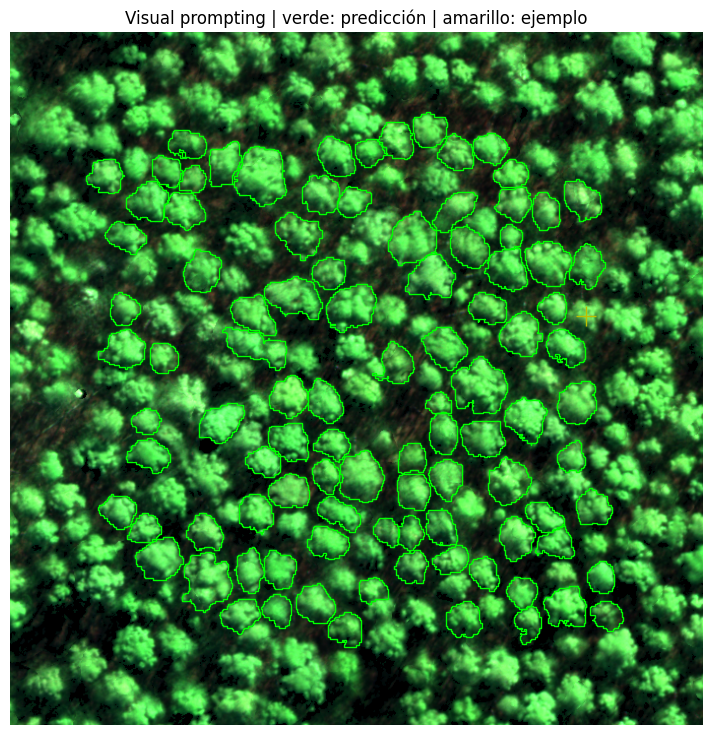

Resultados: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados


In [20]:
from matplotlib.patches import Polygon as PatchPolygon
out=Path(SALIDA)
if len(pred):
    pred.to_file(out/'sam3_visual_copas.gpkg',driver='GPKG')
    pts=pred.copy();pts.geometry=pts.geometry.centroid
    pts.to_file(out/'sam3_visual_centros.gpkg',driver='GPKG')
if len(truth_eval):truth_eval.to_file(out/'sam3_visual_censo_evaluacion.gpkg',driver='GPKG')
pd.DataFrame(tile_records).to_csv(out/'teselas_visual.csv',index=False)
pd.DataFrame(matches,columns=['idx_gt','idx_pred','distancia_m']).to_csv(out/'matches_visual.csv',index=False)
pd.DataFrame([metrics]).to_csv(out/'metricas_visual.csv',index=False)
with open(out/'config_visual.json','w') as f:json.dump(metrics,f,indent=2)
fig,ax=plt.subplots(figsize=(9,9))
e=examples[0];rgb,_=rgb_tile(e['win']);ax.imshow(rgb)
wt=window_transform(e['win'],src.transform)
for _,r in pred[pred.tile_id==e['tile_id']].iterrows():
    from rasterio.transform import rowcol
    xy=[(rowcol(wt,gx,gy)[1],rowcol(wt,gx,gy)[0]) for gx,gy in r.geometry.exterior.coords]
    ax.add_patch(PatchPolygon(xy,fill=False,edgecolor='lime',linewidth=1))
ax.plot(e['example_col'],e['example_row'],'y+',markersize=15)
ax.set(title='Visual prompting | verde: predicción | amarillo: ejemplo');ax.axis('off')
fig.savefig(out/'preview_visual_final.png',dpi=160,bbox_inches='tight');plt.show()
print('Resultados:',out)


### 4.7 Análisis de umbrales

Se conservan las predicciones de la prueba visual inicial y se evalúan distintos umbrales de confianza.

Árboles de referencia: 165
Predicciones disponibles: 98
Score mínimo disponible: 0.185546875
Score máximo disponible: 0.72265625

RESULTADOS POR UMBRAL


,umbral,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct
0,0.10,98,97,1,68,0.9898,0.5879,0.7376,40.6061
1,0.15,98,97,1,68,0.9898,0.5879,0.7376,40.6061
2,0.20,97,96,1,69,0.9897,0.5818,0.7328,41.2121
3,0.25,95,94,1,71,0.9895,0.5697,0.7231,42.4242
4,0.30,93,92,1,73,0.9892,0.5576,0.7132,43.6364
5,0.35,90,89,1,76,0.9889,0.5394,0.6980,45.4545
6,0.40,89,88,1,77,0.9888,0.5333,0.6929,46.0606
7,0.50,74,73,1,92,0.9865,0.4424,0.6109,55.1515



MEJOR UMBRAL ENTRE LOS EVALUADOS
Umbral: 0.1
F1: 0.7376
Precisión: 0.9898
Recall: 0.5879
Detecciones: 98


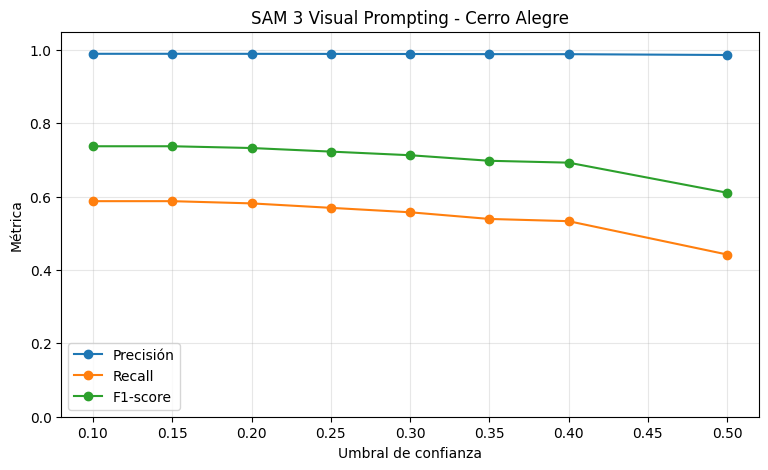

Resultados guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados/comparacion_umbrales_SAM3.csv


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

# Utilizamos las predicciones y referencias de la evaluación anterior
assert "pred" in globals(), "Falta ejecutar la celda que crea pred"
assert "truth_eval" in globals(), "Falta truth_eval"
assert "coverage" in globals(), "Falta coverage"
assert "score" in pred.columns, "Falta columna score"

umbrales = [0.10, 0.15, 0.20, 0.25,
            0.30, 0.35, 0.40, 0.50]

referencia = truth_eval.reset_index(drop=True)
candidatas = pred[
    pred.geometry.centroid.apply(coverage.covers)
].copy()

candidatas = candidatas.reset_index(drop=True)

print("Árboles de referencia:", len(referencia))
print("Predicciones disponibles:", len(candidatas))

if candidatas.empty:
    raise ValueError("No hay predicciones guardadas")

print("Score mínimo disponible:", candidatas.score.min())
print("Score máximo disponible:", candidatas.score.max())

# Matching uno a uno: cada árbol y detección se usan una vez
def evaluar_umbral(umbral):
    detecciones = candidatas[
        candidatas.score >= umbral
    ].reset_index(drop=True)

    A = len(referencia)
    B = len(detecciones)

    if A == 0:
        raise ValueError("No hay árboles de referencia")

    # Costo de no emparejar y costo de pares inválidos
    penalizacion = 10000.0
    costo = np.full((A+B, A+B), 1e7)

    costo[:A, B:] = penalizacion
    costo[A:, :B] = penalizacion
    costo[A:, B:] = 0.0

    for i, pt in enumerate(referencia.geometry):
        for j, pol in enumerate(detecciones.geometry):
            dist = float(pt.distance(pol.centroid))

            if pol.covers(pt):
                costo[i, j] = dist
            elif dist <= DIST_MATCH_M:
                costo[i, j] = DIST_MATCH_M + dist

    if B:
        filas, columnas = linear_sum_assignment(costo)
        TP = sum(
            1 for i, j in zip(filas, columnas)
            if i < A and j < B and costo[i, j] < penalizacion
        )
    else:
        TP = 0

    FP = B - TP
    FN = A - TP

    precision = TP/(TP+FP) if TP+FP else 0
    recall = TP/(TP+FN) if TP+FN else 0
    f1 = (
        2*precision*recall/(precision+recall)
        if precision+recall else 0
    )

    return {
        "umbral": umbral,
        "detecciones": B,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "error_conteo_pct": 100*abs(B-A)/A
    }

resultados = pd.DataFrame([
    evaluar_umbral(t) for t in umbrales
])

print("\nRESULTADOS POR UMBRAL")
display(resultados.round(4))

mejor = resultados.loc[resultados.F1.idxmax()]

print("\nMEJOR UMBRAL ENTRE LOS EVALUADOS")
print("Umbral:", mejor.umbral)
print("F1:", round(mejor.F1, 4))
print("Precisión:", round(mejor.precision, 4))
print("Recall:", round(mejor.recall, 4))
print("Detecciones:", int(mejor.detecciones))

# Gráfico comparativo
plt.figure(figsize=(9, 5))
plt.plot(resultados.umbral, resultados.precision,
         "o-", label="Precisión")
plt.plot(resultados.umbral, resultados.recall,
         "o-", label="Recall")
plt.plot(resultados.umbral, resultados.F1,
         "o-", label="F1-score")

plt.xlabel("Umbral de confianza")
plt.ylabel("Métrica")
plt.title("SAM 3 Visual Prompting - Cerro Alegre")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Guardar resultados
archivo = SALIDA / "comparacion_umbrales_SAM3.csv"
resultados.to_csv(archivo, index=False)
print("Resultados guardados en:", archivo)

## 5. Preparación para pruebas con 1, 3, 5 y 10 copas

### 5.1 Función compartida para preparar las zonas

In [22]:
from rasterio.windows import Window, transform as window_transform
from rasterio.transform import rowcol
from shapely.geometry import box

# Parámetro agregado en la integración: NO estaba definido en los originales.
GAP_FRAC = 0.10

def preparar_zonas(ex):
    '''Prepara la ventana y separa espacialmente ejemplos y evaluación.'''
    win = ex["win"]
    rgb, invalid = rgb_tile(win)
    h, w = rgb.shape[:2]
    tf = window_transform(win, src.transform)

    izquierda = int(w * (0.5 - GAP_FRAC / 2))
    derecha = int(w * (0.5 + GAP_FRAC / 2))
    if not 0 < izquierda < derecha < w:
        raise ValueError("GAP_FRAC no deja sectores válidos")

    def rectangulo(c0, c1):
        p0 = tf * (c0, 0)
        p1 = tf * (c1, h)
        return box(min(p0[0], p1[0]), min(p0[1], p1[1]),
                   max(p0[0], p1[0]), max(p0[1], p1[1]))

    train = rectangulo(0, izquierda)
    test = rectangulo(derecha, w)
    validas = []

    for idx, geom in copas.geometry.items():
        if geom is None or geom.is_empty or not geom.is_valid or geom.area <= 0:
            continue
        if not train.covers(geom):
            continue

        minx, miny, maxx, maxy = geom.bounds
        r0, c0 = rowcol(tf, minx, maxy)
        r1, c1 = rowcol(tf, maxx, miny)
        l, r = sorted((int(c0), int(c1)))
        arriba, abajo = sorted((int(r0), int(r1)))
        if not (0 <= l < r <= izquierda and 0 <= arriba < abajo <= h):
            continue
        if invalid[arriba:abajo, l:r].any():
            continue

        bw, bh = r-l, abajo-arriba
        validas.append({
            "index": idx,
            "area": float(geom.area),
            "pixel_box": (l, arriba, r, abajo),
            "box": [(l+r)/(2*w), (arriba+abajo)/(2*h), bw/w, bh/h]
        })

    return {
        "ex": ex, "win": win, "rgb": rgb, "invalid": invalid,
        "transform": tf, "train": train, "test": test,
        "validas": validas
    }


### 5.2 Selección de teselas y copas

MEJORES TESELAS DISPONIBLES


,opcion,x,y,copas_ejemplo,arboles_evaluacion
5,5,768,2304,45,82
1,1,0,768,24,221
10,10,768,3840,14,218
7,7,768,3072,11,194
16,16,1074,5349,7,38
0,0,0,0,5,187
8,8,1074,3072,3,37
11,11,1074,3840,1,96
3,3,768,1536,1,7
4,4,0,2304,0,285



TESELA ELEGIDA
Copas para prompts: 45
Árboles para evaluación: 82
Experimentos posibles: [1, 3, 5, 10]


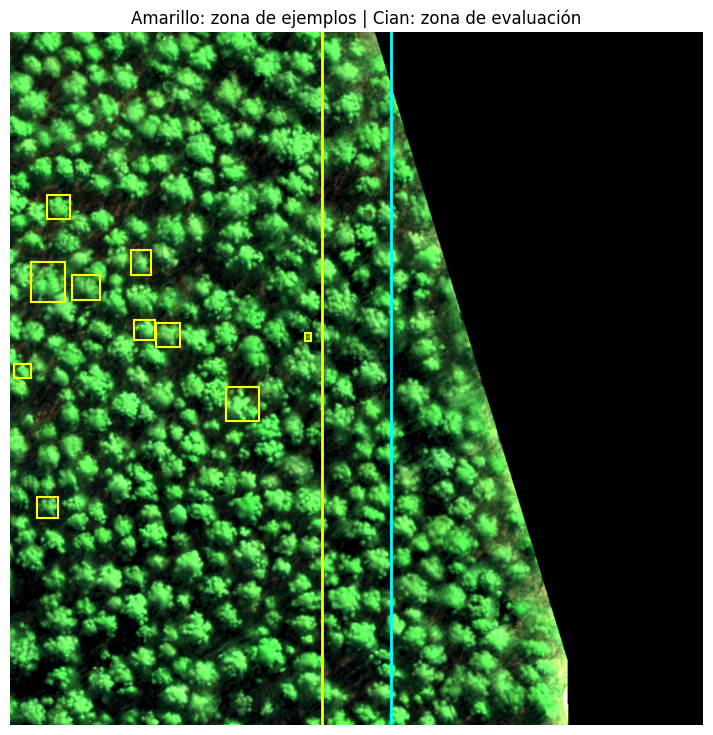

In [23]:
from rasterio.windows import Window
from matplotlib.patches import Rectangle

# Buscar teselas más grandes con suficientes copas
TAM_VENTANA = 1024
PASO = 768
N_EXPERIMENTOS = [1, 3, 5, 10]

def inicios(total, tam, paso):
    if total <= tam:
        return [0]
    posiciones = list(range(0, total-tam+1, paso))
    if posiciones[-1] != total-tam:
        posiciones.append(total-tam)
    return sorted(set(posiciones))

opciones = []
resumen = []

for y in inicios(src.height, TAM_VENTANA, PASO):
    for x in inicios(src.width, TAM_VENTANA, PASO):

        w = min(TAM_VENTANA, src.width-x)
        h = min(TAM_VENTANA, src.height-y)

        ex = {
            "win": Window(x, y, w, h),
            "x": x, "y": y,
            "w": w, "h": h
        }

        opcion = preparar_zonas(ex)

        n_copas = len(opcion["validas"])
        n_test = int(
            truth.geometry.apply(
                opcion["test"].covers
            ).sum()
        )

        if n_test == 0:
            continue

        opciones.append(opcion)

        resumen.append({
            "opcion": len(opciones)-1,
            "x": x,
            "y": y,
            "copas_ejemplo": n_copas,
            "arboles_evaluacion": n_test
        })

ranking = pd.DataFrame(resumen)

assert not ranking.empty, (
    "No se encontraron zonas de evaluación"
)

ranking = ranking.sort_values(
    ["copas_ejemplo", "arboles_evaluacion"],
    ascending=False
)

print("MEJORES TESELAS DISPONIBLES")
display(ranking.head(10))

# Preferir teselas con >=10 ejemplos y >=20 árboles de prueba
aptas = ranking[
    (ranking.copas_ejemplo >= 10) &
    (ranking.arboles_evaluacion >= 20)
]

if len(aptas):
    elegida = aptas.iloc[0]
else:
    elegida = ranking.iloc[0]
    print("No se encontró una tesela con 10 ejemplos y 20 árboles de evaluación.")

datos_exp = opciones[int(elegida["opcion"])]

validas = sorted(
    datos_exp["validas"],
    key=lambda d: d["area"]
)

# Selección distribuida por tamaños
rng = np.random.default_rng(42)

if len(validas) >= 3:
    indices = [0, len(validas)//2, len(validas)-1]
    seleccion = [validas[i] for i in indices]
    restantes = [
        v for j, v in enumerate(validas)
        if j not in indices
    ]
else:
    seleccion = []
    restantes = validas.copy()

orden = rng.permutation(len(restantes))
seleccion += [restantes[int(i)] for i in orden]

print("\nTESELA ELEGIDA")
print("Copas para prompts:", len(seleccion))
print("Árboles para evaluación:",
      int(elegida["arboles_evaluacion"]))
print("Experimentos posibles:",
      [n for n in N_EXPERIMENTOS if n <= len(seleccion)])

# Visualizar separación espacial y ejemplos
rgb = datos_exp["rgb"]
H, W = rgb.shape[:2]

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(rgb)

x_train = W*(0.5-GAP_FRAC/2)
x_test = W*(0.5+GAP_FRAC/2)

ax.axvline(x_train, color="yellow", linewidth=2)
ax.axvline(x_test, color="cyan", linewidth=2)

for p in seleccion[:10]:
    l, t, r, b = p["pixel_box"]
    ax.add_patch(Rectangle(
        (l, t), r-l, b-t,
        fill=False,
        edgecolor="yellow",
        linewidth=1.5
    ))

ax.set_title(
    "Amarillo: zona de ejemplos | "
    "Cian: zona de evaluación"
)
ax.axis("off")
plt.show()

### 5.3 Inferencia con diferentes cantidades de copas

In [24]:
import torch
from rasterio.features import shapes
from shapely.geometry import shape

# Para diagnóstico: conservar candidatos de baja confianza
UMBRAL_INTERNO = 0.01
UMBRAL_ANALISIS = 0.10
MIN_PIXELS_EXP = 18

processor.set_confidence_threshold(UMBRAL_INTERNO)

dtype_exp = (
    torch.bfloat16 if torch.cuda.is_bf16_supported()
    else torch.float16
)

rgb = datos_exp["rgb"]
invalid = datos_exp["invalid"]
tf = datos_exp["transform"]
zona_test = datos_exp["test"]

resultados_brutos = {}

for n in N_EXPERIMENTOS:

    if n > len(seleccion):
        print(f"Se omite {n}: faltan copas válidas")
        continue

    print(f"\nProbando {n} copas reales...")

    # Estado nuevo e independiente para cada experimento
    pil = Image.fromarray(rgb)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=dtype_exp
        ):

            # Crear el estado dentro de autocast
            state = processor.set_image(pil)

            result = None

            # Incorporar las copas como ejemplos positivos
            for ejemplo in seleccion[:n]:
                result = processor.add_geometric_prompt(
                    state=state,
                    box=ejemplo["box"],
                    label=True
                )

    masks = (
        result["masks"]
        .detach().float().cpu().numpy()
    )

    scores = (
        result["scores"]
        .detach().float().cpu().numpy()
        .reshape(-1)
    )

    registros = []

    for score, mask in zip(scores, masks):

        score = float(score)

        if score < UMBRAL_ANALISIS:
            continue

        mask = np.squeeze(mask) > 0.5

        if mask.shape != invalid.shape:
            continue

        mask[invalid] = False

        if mask.sum() < MIN_PIXELS_EXP:
            continue

        geometria = mask_polygon(mask, tf)

        if geometria is None or geometria.is_empty:
            continue

        # Solo detecciones de la zona independiente
        if not zona_test.covers(geometria.centroid):
            continue

        registros.append({
            "score": score,
            "geometry": geometria
        })

    # Eliminar duplicaciones por solapamiento
    registros.sort(key=lambda r: r["score"], reverse=True)

    unicas = []

    for registro in registros:
        duplicada = False

        for anterior in unicas:
            inter = registro["geometry"].intersection(
                anterior["geometry"]
            ).area
            union = registro["geometry"].union(
                anterior["geometry"]
            ).area

            if union > 0 and inter/union >= 0.5:
                duplicada = True
                break

        if not duplicada:
            unicas.append(registro)

    resultados_brutos[n] = unicas

    print("Candidatos SAM 3:", len(scores))
    print("Predicciones únicas en evaluación:",
          len(unicas))
    print("Score máximo:",
          float(scores.max()) if len(scores) else None)

    del pil, state, result, masks, scores

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nInferencia comparativa terminada")


Probando 1 copas reales...
Candidatos SAM 3: 200
Predicciones únicas en evaluación: 25
Score máximo: 0.6953125

Probando 3 copas reales...
Candidatos SAM 3: 200
Predicciones únicas en evaluación: 28
Score máximo: 0.921875

Probando 5 copas reales...
Candidatos SAM 3: 200
Predicciones únicas en evaluación: 24
Score máximo: 0.91796875

Probando 10 copas reales...
Candidatos SAM 3: 200
Predicciones únicas en evaluación: 18
Score máximo: 0.921875

Inferencia comparativa terminada


### 5.4 Métricas para 1, 3, 5 y 10 ejemplos

COMPARACIÓN SAM 3 - CERO ALEGRE


,n_ejemplos,n_censo,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct
0,1,82,25,15,10,67,0.6,0.1829,0.2804,69.5122
1,3,82,28,28,0,54,1.0,0.3415,0.5091,65.8537
2,5,82,24,24,0,58,1.0,0.2927,0.4528,70.7317
3,10,82,18,18,0,64,1.0,0.2195,0.3600,78.0488



MEJOR CONFIGURACIÓN EXPLORATORIA
Ejemplos: 3
Precisión: 1.0
Recall: 0.3415
F1-score: 0.5091


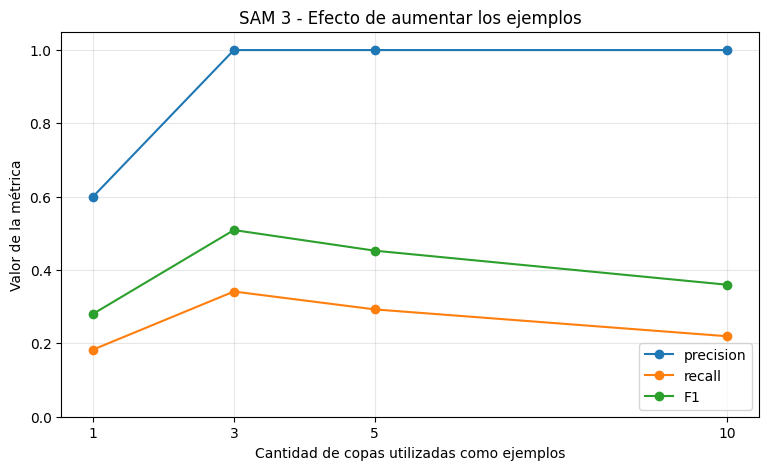

Resultados guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados


In [25]:
from scipy.optimize import linear_sum_assignment
from pathlib import Path

zona_test = datos_exp["test"]

# Puntos censados dentro de la zona de evaluación
ref = truth[
    truth.geometry.apply(zona_test.covers)
].reset_index(drop=True)

A = len(ref)
assert A > 0, "No hay árboles censados en la zona de evaluación"

DISTANCIA = globals().get("DIST_MATCH_M", 2.5)

def evaluar_detecciones(detecciones):
    B = len(detecciones)

    if B == 0:
        return 0, 0, A

    # Matching uno a uno
    penalizacion = 10000.0
    costo = np.full((A+B, A+B), 1e7)

    costo[:A, B:] = penalizacion
    costo[A:, :B] = penalizacion
    costo[A:, B:] = 0

    for i, punto in enumerate(ref.geometry):
        for j, det in enumerate(detecciones):
            pol = det["geometry"]
            distancia = punto.distance(pol.centroid)

            if pol.covers(punto):
                costo[i, j] = distancia
            elif distancia <= DISTANCIA:
                costo[i, j] = DISTANCIA + distancia

    filas, columnas = linear_sum_assignment(costo)

    TP = sum(
        1 for i, j in zip(filas, columnas)
        if i < A and j < B
        and costo[i, j] < penalizacion
    )

    return TP, B-TP, A-TP

metricas_exp = []

for n, detecciones in resultados_brutos.items():

    TP, FP, FN = evaluar_detecciones(detecciones)
    B = len(detecciones)

    precision = TP/(TP+FP) if TP+FP else 0
    recall = TP/(TP+FN) if TP+FN else 0
    f1 = (
        2*precision*recall/(precision+recall)
        if precision+recall else 0
    )

    metricas_exp.append({
        "n_ejemplos": n,
        "n_censo": A,
        "detecciones": B,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "error_conteo_pct": 100*abs(B-A)/A
    })

comparacion = pd.DataFrame(metricas_exp).sort_values(
    "n_ejemplos"
)

print("COMPARACIÓN SAM 3 - CERO ALEGRE")
display(comparacion.round(4))

mejor = comparacion.loc[comparacion["F1"].idxmax()]

print("\nMEJOR CONFIGURACIÓN EXPLORATORIA")
print("Ejemplos:", int(mejor["n_ejemplos"]))
print("Precisión:", round(mejor["precision"], 4))
print("Recall:", round(mejor["recall"], 4))
print("F1-score:", round(mejor["F1"], 4))

plt.figure(figsize=(9, 5))

for metrica in ["precision", "recall", "F1"]:
    plt.plot(
        comparacion["n_ejemplos"],
        comparacion[metrica],
        marker="o",
        label=metrica
    )

plt.xlabel("Cantidad de copas utilizadas como ejemplos")
plt.ylabel("Valor de la métrica")
plt.title("SAM 3 - Efecto de aumentar los ejemplos")
plt.ylim(0, 1.05)
plt.xticks(comparacion["n_ejemplos"])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Guardar los resultados
destino = Path(SALIDA)
destino.mkdir(parents=True, exist_ok=True)

comparacion.to_csv(
    destino / "SAM3_comparacion_cantidad_ejemplos.csv",
    index=False
)

print("Resultados guardados en:", destino)

## 6. Evaluación en varias zonas

### 6.1 Selección de zonas independientes

Zonas independientes seleccionadas: 3
Zona 1: 24 copas disponibles, 221 árboles de evaluación, 76.5% de imagen válida en test


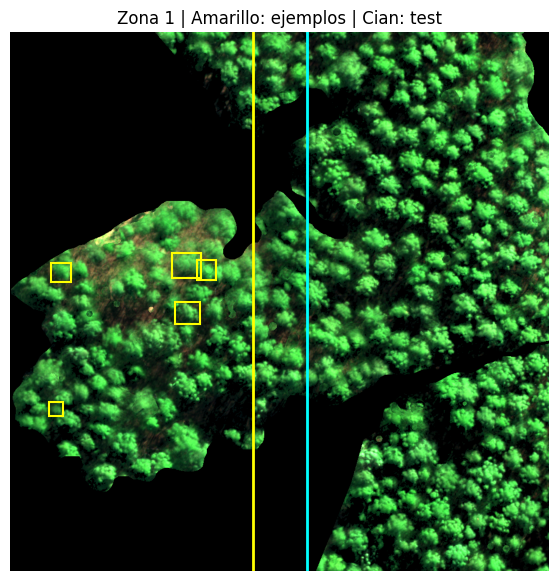

Zona 2: 14 copas disponibles, 218 árboles de evaluación, 73.5% de imagen válida en test


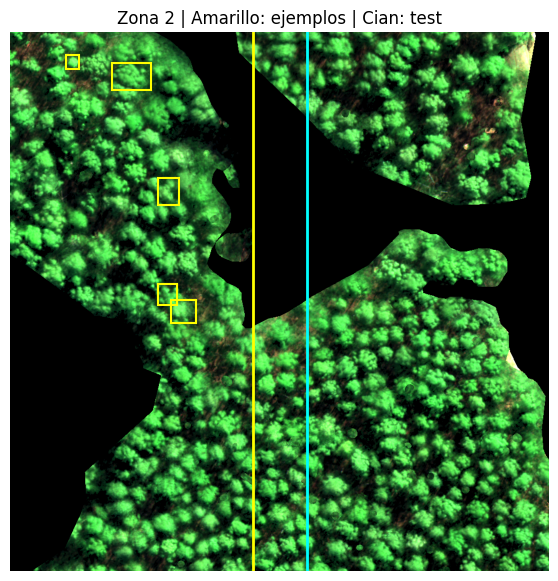

Zona 3: 45 copas disponibles, 82 árboles de evaluación, 27.6% de imagen válida en test


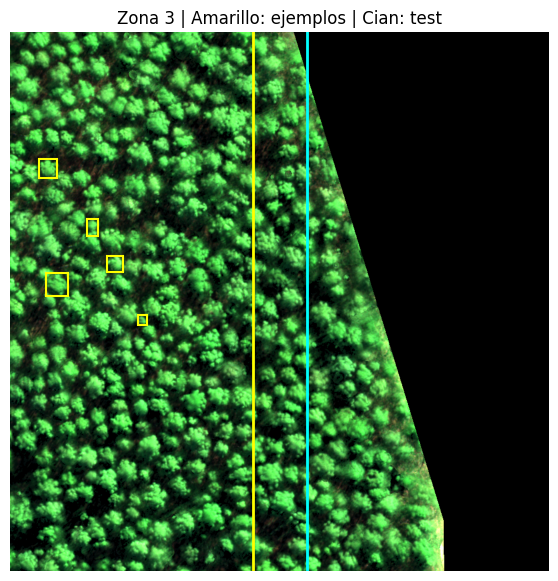

In [26]:

# Se mantienen los criterios del original: máximo de tres zonas, al menos cinco copas para ejemplos
# y veinte árboles de prueba, con un mínimo del 25 % de cobertura válida en el sector de evaluación.

CANTIDADES = [1, 3, 5]
UMBRALES = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
MAX_ZONAS = 3
MIN_EJEMPLOS = 5
MIN_ARBOLES_TEST = 20
MIN_FRACCION_VALIDA_TEST = 0.25

# Crear ranking con cobertura válida en la zona de prueba
candidatas = []

for i, d in enumerate(opciones):
    ex = d["ex"]
    n = len(d["validas"])
    n_test = int(truth.geometry.apply(d["test"].covers).sum())

    # Porción derecha de la imagen = zona de prueba
    H, W = d["invalid"].shape
    inicio_test = int(W * (0.5 + GAP_FRAC/2))
    fraccion_valida = float((~d["invalid"][:, inicio_test:]).mean())

    if n < MIN_EJEMPLOS or n_test < MIN_ARBOLES_TEST:
        continue

    if fraccion_valida < MIN_FRACCION_VALIDA_TEST:
        continue

    candidatas.append({
        "indice": i,
        "copas": n,
        "n_test": n_test,
        "valid_frac_test": fraccion_valida,
        "x": ex["x"],
        "y": ex["y"],
        "w": ex["w"],
        "h": ex["h"]
    })

ranking_final = pd.DataFrame(candidatas)
ranking_final = ranking_final.sort_values(
    ["valid_frac_test", "copas", "n_test"],
    ascending=False
)

# Seleccionar ventanas sin superposición espacial
zonas_finales = []

for _, fila in ranking_final.iterrows():
    d = opciones[int(fila["indice"])]
    ex = d["ex"]
    rect = box(ex["x"], ex["y"], ex["x"] + ex["w"], ex["y"] + ex["h"])

    if any(rect.intersection(z["rect"]).area > 0 for z in zonas_finales):
        continue

    # Ordenar las copas por tamaño
    validas = sorted(d["validas"], key=lambda v: v["area"])

    # Orden anidado:
    # 1 = mediana
    # 3 = mediana, pequeña, grande
    # 5 = anteriores + dos tamaños intermedios
    L = len(validas)
    indices = [L//2, L//10, 9*L//10, 3*L//10, 7*L//10]

    seleccion = []
    usados = set()

    for idx in indices:
        idx = min(idx, L-1)
        if idx not in usados:
            seleccion.append(validas[idx])
            usados.add(idx)

    if len(seleccion) < 5:
        continue

    zonas_finales.append({
        "datos": d,
        "seleccion": seleccion,
        "rect": rect,
        "n_test": int(fila["n_test"]),
        "valid_frac": float(fila["valid_frac_test"])
    })

    if len(zonas_finales) >= MAX_ZONAS:
        break

print("Zonas independientes seleccionadas:", len(zonas_finales))
assert zonas_finales, "No se encontraron zonas aptas"

for i, z in enumerate(zonas_finales, 1):
    print(
        f"Zona {i}:",
        f"{len(z['datos']['validas'])} copas disponibles,",
        f"{z['n_test']} árboles de evaluación,",
        f"{z['valid_frac']:.1%} de imagen válida en test"
    )

    rgb = z["datos"]["rgb"]
    H, W = rgb.shape[:2]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(rgb)

    # Límites de las dos zonas
    ax.axvline(W*(0.5-GAP_FRAC/2), color="yellow", linewidth=2)
    ax.axvline(W*(0.5+GAP_FRAC/2), color="cyan", linewidth=2)

    for p in z["seleccion"][:5]:
        l, t, r, b = p["pixel_box"]
        ax.add_patch(Rectangle(
            (l, t), r-l, b-t,
            fill=False,
            edgecolor="yellow",
            linewidth=1.5
        ))

    ax.set_title(f"Zona {i} | Amarillo: ejemplos | Cian: test")
    ax.axis("off")
    plt.show()

### 6.2 Inferencia visual en las zonas seleccionadas

In [27]:
import torch
from PIL import Image

model.eval()
processor.set_confidence_threshold(0.0)

TIPO_GPU = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

predicciones_finales = {}
diagnostico_final = []

for zi, zona in enumerate(zonas_finales, 1):

    d = zona["datos"]
    rgb = d["rgb"]
    invalid = d["invalid"]
    tf = d["transform"]
    test = d["test"]

    for n in CANTIDADES:

        print(f"\nZona {zi} | {n} ejemplos")

        pil = Image.fromarray(rgb)

        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                dtype=TIPO_GPU
            ):

                state = processor.set_image(pil)
                result = None

                for ejemplo in zona["seleccion"][:n]:
                    result = processor.add_geometric_prompt(
                        state=state,
                        box=ejemplo["box"],
                        label=True
                    )

        if result is None:
            continue

        masks = result["masks"].detach().float().cpu().numpy()
        scores = result["scores"].detach().float().cpu().numpy().reshape(-1)

        registros = []

        for score, mask in zip(scores, masks):

            score = float(score)

            if score < min(UMBRALES):
                continue

            mask = np.squeeze(mask) > 0.5

            if mask.shape != invalid.shape:
                continue

            mask = mask.copy()
            mask[invalid] = False

            if mask.sum() < 18:
                continue

            geom = mask_polygon(mask, tf)

            if geom is None or geom.is_empty:
                continue

            if not test.covers(geom.centroid):
                continue

            registros.append({
                "score": score,
                "geometry": geom
            })

        # Eliminar máscaras repetidas conservando la de mayor puntuación
        registros.sort(
            key=lambda r: r["score"],
            reverse=True
        )

        unicas = []

        for candidato in registros:
            duplicado = False

            for previo in unicas:
                g1 = candidato["geometry"]
                g2 = previo["geometry"]

                inter = g1.intersection(g2).area
                union = g1.union(g2).area

                if union > 0 and inter/union >= 0.5:
                    duplicado = True
                    break

            if not duplicado:
                unicas.append(candidato)

        predicciones_finales[(zi, n)] = unicas

        diagnostico_final.append({
            "zona": zi,
            "ejemplos": n,
            "candidatos_modelo": len(scores),
            "detecciones_guardadas": len(unicas),
            "score_max": (
                float(scores.max()) if len(scores) else np.nan
            )
        })

        print("Candidatos:", len(scores))
        print("Detecciones únicas en test:", len(unicas))

        del state, result, pil, masks, scores

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\nINFERENCIA COMPLETADA")
display(pd.DataFrame(diagnostico_final))


Zona 1 | 1 ejemplos
Candidatos: 200
Detecciones únicas en test: 98

Zona 1 | 3 ejemplos
Candidatos: 200
Detecciones únicas en test: 94

Zona 1 | 5 ejemplos
Candidatos: 200
Detecciones únicas en test: 91

Zona 2 | 1 ejemplos
Candidatos: 200
Detecciones únicas en test: 92

Zona 2 | 3 ejemplos
Candidatos: 200
Detecciones únicas en test: 83

Zona 2 | 5 ejemplos
Candidatos: 200
Detecciones únicas en test: 79

Zona 3 | 1 ejemplos
Candidatos: 200
Detecciones únicas en test: 25

Zona 3 | 3 ejemplos
Candidatos: 200
Detecciones únicas en test: 24

Zona 3 | 5 ejemplos
Candidatos: 200
Detecciones únicas en test: 21

INFERENCIA COMPLETADA


,zona,ejemplos,candidatos_modelo,detecciones_guardadas,score_max
0,1,1,200,98,0.937500
1,1,3,200,94,0.925781
2,1,5,200,91,0.921875
3,2,1,200,92,0.871094
4,2,3,200,83,0.921875
5,2,5,200,79,0.917969
6,3,1,200,25,0.933594
7,3,3,200,24,0.910156
8,3,5,200,21,0.925781


### 6.3 Evaluación y selección exploratoria de configuración

El promedio de métricas es la media aritmética entre zonas, no una evaluación conjunta de todas las detecciones.

MEJORES CONFIGURACIONES EXPLORATORIAS


,ejemplos,umbral,F1_promedio,F1_minimo,precision_promedio,recall_promedio,error_conteo_promedio,zonas
0,1,0.05,0.5584,0.4673,1.0000,0.3901,60.9888,3
1,1,0.10,0.5494,0.4673,1.0000,0.3810,61.9021,3
7,3,0.05,0.5337,0.4528,1.0000,0.3663,63.3748,3
2,1,0.15,0.5324,0.4673,1.0000,0.3643,63.5737,3
8,3,0.10,0.5257,0.4381,1.0000,0.3591,64.0850,3
14,5,0.05,0.5077,0.4078,1.0000,0.3434,65.6584,3
15,5,0.10,0.5045,0.4078,1.0000,0.3404,65.9621,3
9,3,0.15,0.5017,0.4231,1.0000,0.3369,66.3139,3
3,1,0.20,0.4901,0.4078,1.0000,0.3267,67.3279,3
16,5,0.15,0.4819,0.3922,1.0000,0.3197,68.0299,3



CONFIGURACIÓN CON MAYOR F1 PROMEDIO
Copas de ejemplo: 1
Umbral: 0.05
F1 promedio: 0.5584
Recall promedio: 0.3901
Precisión promedio: 1.0


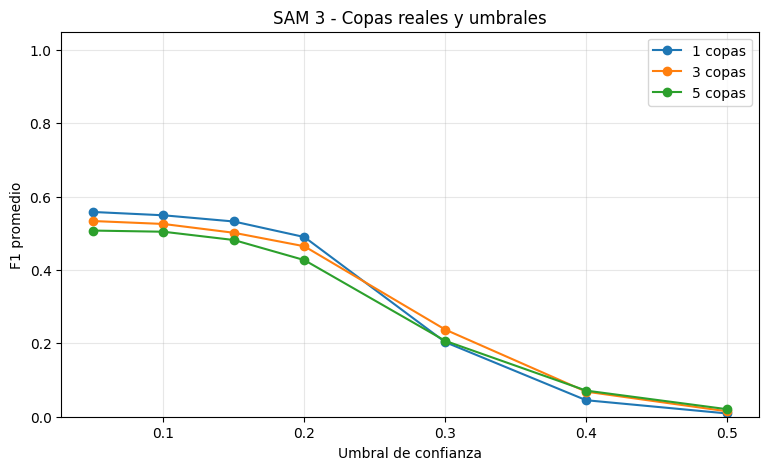

Resultados guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados


In [28]:
from scipy.optimize import linear_sum_assignment
from pathlib import Path

DISTANCIA = globals().get("DIST_MATCH_M", 2.5)

def evaluar_zona(referencia, detecciones):
    A = len(referencia)
    B = len(detecciones)

    if A == 0:
        return None

    if B == 0:
        return 0, 0, A

    # Matching uno a uno
    penalizacion = 10000.0
    costo = np.full((A+B, A+B), 1e7)

    costo[:A, B:] = penalizacion
    costo[A:, :B] = penalizacion
    costo[A:, B:] = 0

    for i, punto in enumerate(referencia.geometry):
        for j, det in enumerate(detecciones):
            pol = det["geometry"]
            dist = float(punto.distance(pol.centroid))

            if pol.covers(punto):
                costo[i, j] = dist
            elif dist <= DISTANCIA:
                costo[i, j] = DISTANCIA + dist

    filas, columnas = linear_sum_assignment(costo)

    TP = sum(
        1 for i, j in zip(filas, columnas)
        if i < A and j < B
        and costo[i, j] < penalizacion
    )

    return TP, B-TP, A-TP


filas_resultados = []

for zi, zona in enumerate(zonas_finales, 1):

    ref = truth[
        truth.geometry.apply(
            zona["datos"]["test"].covers
        )
    ].reset_index(drop=True)

    A = len(ref)

    for n in CANTIDADES:
        candidatas = predicciones_finales.get((zi, n), [])

        for umbral in UMBRALES:

            detecciones = [
                d for d in candidatas
                if d["score"] >= umbral
            ]

            resultado = evaluar_zona(ref, detecciones)

            if resultado is None:
                continue

            TP, FP, FN = resultado
            B = len(detecciones)

            precision = TP/(TP+FP) if TP+FP else 0
            recall = TP/(TP+FN) if TP+FN else 0
            f1 = (
                2*precision*recall/(precision+recall)
                if precision+recall else 0
            )

            filas_resultados.append({
                "zona": zi,
                "ejemplos": n,
                "umbral": umbral,
                "n_censo": A,
                "detecciones": B,
                "TP": TP,
                "FP": FP,
                "FN": FN,
                "precision": precision,
                "recall": recall,
                "F1": f1,
                "error_conteo_pct": 100*abs(B-A)/A
            })

resultados_finales = pd.DataFrame(filas_resultados)

assert not resultados_finales.empty, (
    "No se generaron resultados para evaluar"
)

# Promedio de métricas por zona
resumen_final = (
    resultados_finales
    .groupby(["ejemplos", "umbral"], as_index=False)
    .agg(
        F1_promedio=("F1", "mean"),
        F1_minimo=("F1", "min"),
        precision_promedio=("precision", "mean"),
        recall_promedio=("recall", "mean"),
        error_conteo_promedio=("error_conteo_pct", "mean"),
        zonas=("zona", "nunique")
    )
    .sort_values("F1_promedio", ascending=False)
)

print("MEJORES CONFIGURACIONES EXPLORATORIAS")
display(resumen_final.head(15).round(4))

mejor = resumen_final.iloc[0]

print("\nCONFIGURACIÓN CON MAYOR F1 PROMEDIO")
print("Copas de ejemplo:", int(mejor["ejemplos"]))
print("Umbral:", mejor["umbral"])
print("F1 promedio:", round(mejor["F1_promedio"], 4))
print("Recall promedio:", round(mejor["recall_promedio"], 4))
print("Precisión promedio:", round(mejor["precision_promedio"], 4))

# Gráfico para comparar cantidad de ejemplos
plt.figure(figsize=(9, 5))

for n in CANTIDADES:
    parte = resumen_final[
        resumen_final["ejemplos"] == n
    ].sort_values("umbral")

    plt.plot(
        parte["umbral"],
        parte["F1_promedio"],
        marker="o",
        label=f"{n} copas"
    )

plt.xlabel("Umbral de confianza")
plt.ylabel("F1 promedio")
plt.title("SAM 3 - Copas reales y umbrales")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

destino = Path(SALIDA)
destino.mkdir(parents=True, exist_ok=True)

resultados_finales.to_csv(
    destino / "SAM3_evaluacion_por_zona.csv",
    index=False
)

resumen_final.to_csv(
    destino / "SAM3_optimizacion_final.csv",
    index=False
)

print("Resultados guardados en:", destino)

## 7. Tabla consolidada calculada

In [29]:
# Consolidación automática de los experimentos ejecutados.
filas = []

def agregar(nombre, censo, detecciones, precision, recall, f1):
    filas.append({
        "Experimento": nombre,
        "Árboles de referencia": censo,
        "Detecciones": detecciones,
        "Precisión": precision,
        "Recall": recall,
        "F1": f1
    })

m = metricas_textuales
agregar("Indicación textual, 1 tesela de 768 px",
        m["n_gt"], m["n_pred"], m["precision"], m["recall"], m["F1"])

m = metricas_visual_inicial
agregar("Indicación visual, 1 copa de ejemplo, 1 tesela",
        m["n_gt"], m["n_pred"], m["precision"], m["recall"], m["F1"])

for n in [1, 3, 5, 10]:
    parte = comparacion.loc[comparacion["n_ejemplos"] == n]
    if parte.empty:
        print(f"No se ejecutó el experimento de {n} copas.")
        continue
    r = parte.iloc[0]
    agregar(f"Indicación visual, {n} copa(s), misma tesela",
            int(r["n_censo"]), int(r["detecciones"]),
            r["precision"], r["recall"], r["F1"])

# La comparación entre tres zonas usa exclusivamente una copa y umbral 0,05.
zonas = resultados_finales.loc[
    (resultados_finales["ejemplos"] == 1) &
    (np.isclose(resultados_finales["umbral"], 0.05))
].copy()

if zonas["zona"].nunique() == 3:
    agregar("Indicación visual, promedio de 3 zonas (1 copa, umbral 0,05)",
            None, None,
            zonas["precision"].mean(),
            zonas["recall"].mean(),
            zonas["F1"].mean())
else:
    print("Promedio de 3 zonas omitido: no hay resultados de tres zonas independientes.")

tabla_comparativa = pd.DataFrame(filas)
display(tabla_comparativa.round(3))
archivo_tabla = Path(SALIDA) / "SAM3_tabla_comparativa_automatica.csv"
tabla_comparativa.to_csv(archivo_tabla, index=False)
print("Tabla guardada:", archivo_tabla)


,Experimento,Árboles de referencia,Detecciones,Precisión,Recall,F1
0,"Indicación textual, 1 tesela de 768 px",302.0,7.0,1.00,0.023,0.045
1,"Indicación visual, 1 copa de ejemplo, 1 tesela",165.0,98.0,0.99,0.588,0.738
2,"Indicación visual, 1 copa(s), misma tesela",82.0,25.0,0.60,0.183,0.280
3,"Indicación visual, 3 copa(s), misma tesela",82.0,28.0,1.00,0.341,0.509
4,"Indicación visual, 5 copa(s), misma tesela",82.0,24.0,1.00,0.293,0.453
5,"Indicación visual, 10 copa(s), misma tesela",82.0,18.0,1.00,0.220,0.360
6,"Indicación visual, promedio de 3 zonas (1 copa...",NaN,NaN,1.00,0.390,0.558


Tabla guardada: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/SAM3_CerroAlegre_VisualPrompt_Copas_Resultados/SAM3_tabla_comparativa_automatica.csv
